In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Used_Cars_Homework.csv")

display(df.head())
print("Размер:", df.shape)
print("\nТипы данных:\n", df.dtypes)
print("\nПропуски:\n", df.isnull().sum())
display(df.describe())

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672


Размер: (300, 9)

Типы данных:
 age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

Пропуски:
 age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64


,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


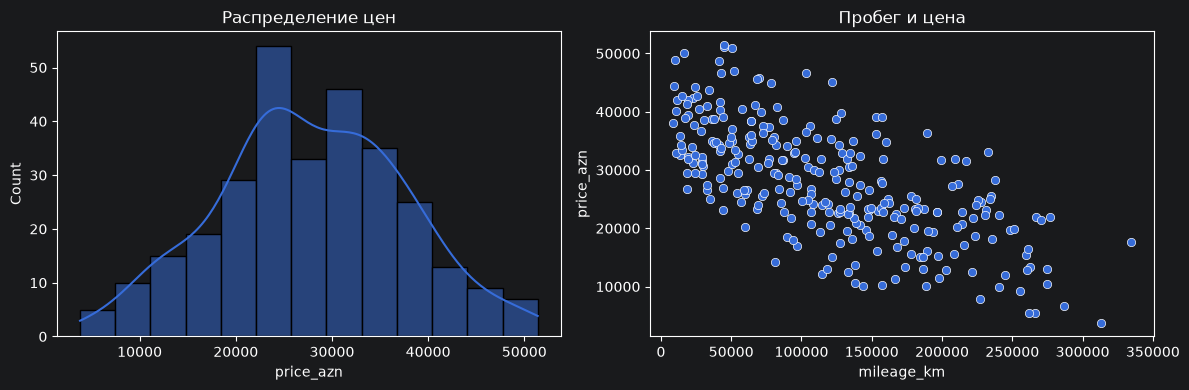

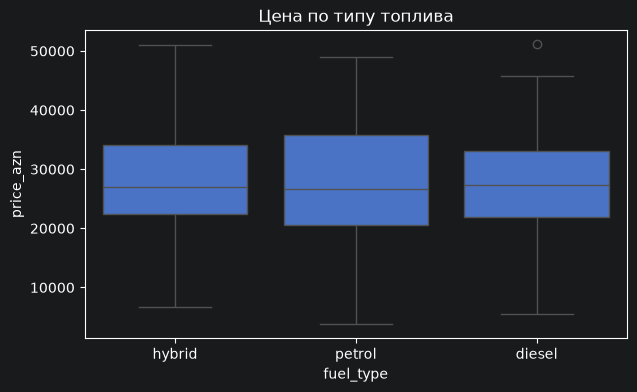

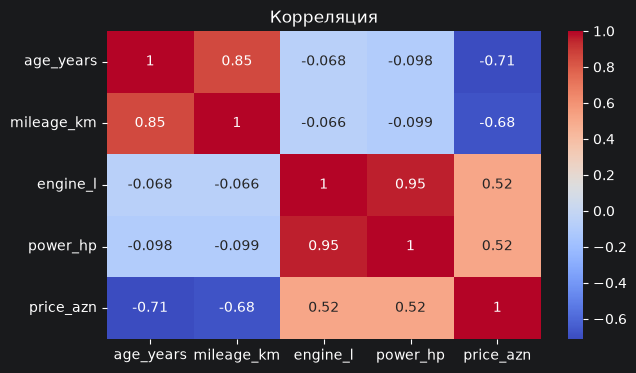

In [2]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df["price_azn"], kde=True)
plt.title("Распределение цен")

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x="mileage_km", y="price_azn")
plt.title("Пробег и цена")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="fuel_type", y="price_azn")
plt.title("Цена по типу топлива")
plt.show()

plt.figure(figsize=(7, 4))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.title("Корреляция")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

df["mileage_per_year"] = df["mileage_km"] / df["age_years"].replace(0, 1)

X = df.drop("price_azn", axis=1)
y = df["price_azn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Factorize:", pd.factorize(df["brand"])[0][:10])
print("One-Hot:\n", pd.get_dummies(df["brand"]).head())

print("MinMax:\n", MinMaxScaler().fit_transform(df[["mileage_km"]])[:5])
print("Standard:\n", StandardScaler().fit_transform(df[["mileage_km"]])[:5])

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

Factorize: [0 1 2 3 1 0 2 1 0 1]
One-Hot:
      BMW  Hyundai    Kia  Toyota
0  False     True  False   False
1   True    False  False   False
2  False    False  False    True
3  False    False   True   False
4   True    False  False   False
MinMax:
 [[0.27147577]
 [0.20169448]
 [0.1862544 ]
 [0.36119283]
 [0.10246403]]
Standard:
 [[-0.28886923]
 [-0.59794777]
 [-0.66633568]
 [ 0.10850968]
 [-1.03746386]]


In [4]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(random_state=42))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2:", r2_score(y_test, predictions))

display(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
}).head(10))

new_cars = pd.DataFrame([
    [5, 75000, 1.6, 110, "Toyota", "Petrol", "Automatic", "No"],
    [10, 180000, 2.0, 140, "Hyundai", "Diesel", "Manual", "Yes"],
    [3, 40000, 2.5, 170, "BMW", "Petrol", "Automatic", "No"]
], columns=["age_years", "mileage_km", "engine_l", "power_hp",
            "brand", "fuel_type", "transmission", "accident_history"])

new_cars["mileage_per_year"] = (
    new_cars["mileage_km"] / new_cars["age_years"].replace(0, 1)
)

new_cars["Predicted Price"] = model.predict(new_cars)
display(new_cars)

MAE: 1888.2146143803523
MSE: 5321858.300409844
RMSE: 2306.915321464974
R2: 0.9479464213092695


,Actual,Predicted
0,34837,30509.154468
1,34946,30801.234303
2,32214,30857.810220
3,36190,38204.089588
4,25000,27842.279737
5,26522,28911.870886
6,22711,20265.358920
7,33061,34532.940064
8,18479,18075.720398
9,25003,25751.025903


,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year,Predicted Price
0,5,75000,1.6,110,Toyota,Petrol,Automatic,No,15000.000000,29668.784286
1,10,180000,2.0,140,Hyundai,Diesel,Manual,Yes,18000.000000,23468.416979
2,3,40000,2.5,170,BMW,Petrol,Automatic,No,13333.333333,44086.043575


Conclusion
The Gradient Boosting algorithm was applied to forecast used car prices. The model's accuracy was checked using MAE, MSE, RMSE, and R² metrics. Additionally, it predicted the estimated prices of three new cars.